# Paper figures (`main.tex`)

Minor refactor of `moving_retina_2.ipynb` that writes the linear-model figures used in the paper.

| File | Caption in `main.tex` |
|---|---|
| `results/emp_vs_analytic.pdf` | Drifting natural images vs analytic model |
| `results/spatial_temporal_spectra_for_different_betas.pdf` | Spectra for different $\beta$ |
| `results/optimal_filter.pdf` | Optimal filter and kernel |
| `results/optimal_diffusion_constant_vs_input_output_noise.pdf` | Left: $I$ vs $D$ for three noise levels; right: $D^*$ across input/output noise |

`results/combined_fig.pdf` (linear-nonlinear weights) is not produced here.

In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from tqdm import tqdm

from scipy.optimize import brentq, minimize_scalar

ROOT = Path().resolve().parents[0]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],
    "font.size": 7,
})
plt.style.use("../../paper.mplstyle")

%reload_ext autoreload
%autoreload 2

cm = 1 / 2.54
fw = 17.8 * cm
hw = 8.7 * cm


In [24]:
def vk_analytical(Cx, lam, N_in, N_out, cost=None):
    if cost is None:
        cost = np.ones_like(Cx)

    v = np.zeros_like(Cx, dtype=float)
    mask = Cx > 0
    ratio = Cx[mask] / (Cx[mask] + N_in)
    lam_eff = lam * cost[mask]
    inner = np.sqrt(1.0 + (N_in / N_out) * 2.0 / (lam_eff * Cx[mask]))
    raw = (N_out / N_in) * (ratio * 0.5 * (inner + 1.0) - 1.0)
    v[mask] = np.maximum(raw, 0.0)
    return v


def power_residual(Cx, log_lam, N_in, N_out, weights, cost):
    lam = np.exp(log_lam)
    v = vk_analytical(Cx, lam, N_in, N_out, cost=cost)
    return np.sum(weights * cost * (Cx + N_in) * v) - 1


def Cx_separable(k, w, alpha=2.0, beta=1.3):
    return 1.0 / (k[:, None] ** alpha * np.maximum(w[None, :], 1e-4) ** beta)


def Cx_drift(sf, tf, D, alpha=2.0, signal_scale=1e0):
    k = 2 * np.pi * sf
    w = 2 * np.pi * tf
    Dk2 = D * k[:, None] ** 2
    Cs = k[:, None] ** (-alpha)
    w2 = w[None, :] ** 2
    return signal_scale * 2 * Dk2 * Cs / (Dk2 ** 2 + w2)


def brownian_probability_1d(x, D, t):
    return 1 / np.sqrt(4 * np.pi * D * t) * np.exp(-x ** 2 / (4 * D * t))


def mutual_information(
    sf, tf, weights, D, N_in, N_out, alpha=2.0, c=0.0, separable=False, temporal_cost_function=None
):
    if temporal_cost_function is None:
        raise NotImplementedError("Temporal cost function not implemented")
    Cx = Cx_separable(sf, tf, alpha=alpha) if separable else Cx_drift(sf, tf, D, alpha=alpha)
    cost = 1.0 + c * temporal_cost_function(tf[None, :])
    cost = np.broadcast_to(cost, Cx.shape)

    pr = lambda log_lam: power_residual(Cx, log_lam, N_in, N_out, weights, cost)
    log_lam_opt = brentq(pr, -50.0, 50.0, xtol=1e-12)
    v_opt = vk_analytical(Cx, np.exp(log_lam_opt), N_in, N_out, cost=cost)
    snr = Cx * v_opt / (N_in * v_opt + N_out)
    MI = 0.5 * np.sum(weights * np.log1p(snr))
    return Cx, v_opt, MI


def minimum_phase_rfft_from_magnitude(amp, axis=-1, eps=1e-12):
    amp = np.maximum(np.asarray(amp, dtype=float), eps)
    log_amp = np.log(amp)
    cep = np.fft.irfft(log_amp, axis=axis).real
    n = amp.shape[axis]
    cep_min = np.zeros_like(cep)
    idx = [slice(None)] * amp.ndim
    idx[axis] = 0
    cep_min[tuple(idx)] = cep[tuple(idx)]
    if n % 2 == 0:
        idx_pos = list(idx)
        idx_pos[axis] = slice(1, n // 2)
        cep_min[tuple(idx_pos)] = 2.0 * cep[tuple(idx_pos)]
        idx_nyq = list(idx)
        idx_nyq[axis] = n // 2
        cep_min[tuple(idx_nyq)] = cep[tuple(idx_nyq)]
    else:
        idx_pos = list(idx)
        idx_pos[axis] = slice(1, (n + 1) // 2)
        cep_min[tuple(idx_pos)] = 2.0 * cep[tuple(idx_pos)]
    log_H = np.fft.fft(cep_min, axis=axis)
    return np.exp(log_H)


def compute_space_time_filter(v_opt, T, dt, dx, K):
    amp = np.sqrt(np.maximum(v_opt, 0.0))
    floor = 1e-3 * max(float(np.nanmax(amp)), 1e-300)
    amp = np.maximum(amp, floor)
    H_k_w = minimum_phase_rfft_from_magnitude(amp, axis=1)
    H_spatial_centered = np.concatenate([H_k_w[::-1, :], H_k_w], axis=0)
    H = np.fft.ifftshift(H_spatial_centered, axes=0)
    w_xt = np.fft.ifft(np.fft.irfft(H, n=T, axis=1), axis=0).real
    w_xt_plot = np.fft.fftshift(w_xt, axes=0)
    x = (np.arange(K) - K // 2) * dx
    t = np.arange(T) * dt
    return w_xt_plot, x, t


def plot_contours(ax, x, y, z, levels, lw=1, cmap="magma"):
    c = ax.contourf(x, y, z.T, levels=levels, cmap=cmap, extend="both")
    ax.contour(x, y, z.T, levels=levels, colors="k", linewidths=lw, linestyles="solid", negative_linestyle="solid")
    return c


def plain_formatter():
    return FuncFormatter(lambda value, position: f"{value:g}")


def find_eta_given_diffusion_constant(
    sf, tf, weights, D_deg, N_in, N_out, alpha=2.0, 
    separable=False, temporal_cost_function=None,delta=0.001):
    """Maximize MI over D assuming an upside-down U (unimodal); tolerance `delta` in arcmin^2/s."""
    def neg_MI(c):
        _, _, MI = mutual_information(
            sf,
            tf,
            weights,
            D_deg,
            N_in,
            N_out,
            alpha,
            separable=separable,
            c=c,
            temporal_cost_function=temporal_cost_function,
        )
        return -MI

    
    res = minimize_scalar(
        neg_MI,
        method="bounded",
        bounds = (1e-10,1e3),
        options={"xatol": delta},
    )
    return res.x


def find_diffusion_constant_give_eta(
    sf, tf, weights, N_in, N_out, c, alpha=2.0, 
    separable=False, temporal_cost_function=None,delta=0.001):
    """Maximize MI over D assuming an upside-down U (unimodal); tolerance `delta` in arcmin^2/s."""
    def neg_MI(D_deg):
        _, _, MI = mutual_information(
            sf,
            tf,
            weights,
            D_deg,
            N_in,
            N_out,
            alpha,
            separable=separable,
            c=c,
            temporal_cost_function=temporal_cost_function,
        )
        return -MI

    
    res = minimize_scalar(
        neg_MI,
        method="bounded",
        bounds = (1e-10,1e3),
        options={"xatol": delta},
    )
    return res.x


def plot_and_save_optimal_filter(v_opt,fname,max_time = 0.5,max_space=0.15,ylim_slice=(-6,3)):
    plot_filter = np.log10(np.clip(v_opt, 1e-12, None))[np.ix_(sf_mask, tf_mask)]
    filter_levels = np.arange(-4, np.ceil(np.nanmax([plot_filter.max()])) + 1, 1)

    fig = plt.figure(figsize=(fw, 1.2 * hw))
    g = fig.add_gridspec(2, 4, hspace=0.45, wspace=0.42,height_ratios=[1,0.75])

    ax_signal = fig.add_subplot(g[0, 0])
    c_signal = plot_contours(ax_signal, sf_plot, tf_plot, plot_analytic, levels)

    ax_filter = fig.add_subplot(g[0, 1], sharey=ax_signal)
    c_filter = plot_contours(ax_filter, sf_plot, tf_plot, plot_filter, filter_levels)

    w_xt_plot, x, t = compute_space_time_filter(v_opt, T, dt, dx, K)
    ax_kernel = fig.add_subplot(g[1, :1])
    vmag = np.abs(w_xt_plot).max()
    ax_kernel.imshow(
        w_xt_plot, aspect="auto", origin="lower",
        extent=[t[0], t[-1], x[0], x[-1]], cmap="RdBu", vmin=-vmag, vmax=vmag,
    )
    ax_kernel.set_xlabel("time [sec]")
    ax_kernel.set_ylabel("space")
    ax_kernel.set_xlim([0, max_time])
    ax_kernel.set_ylim([-max_space, max_space])

    ax_spatial_slice = fig.add_subplot(g[1, 2])
    arg_slice = w_xt_plot[w_xt_plot.shape[0] // 2, :].argmax()
    spatial_slice = w_xt_plot[:, arg_slice]
    ax_kernel.axvline(t[arg_slice], color="k", alpha=0.5, linestyle=":")
    ax_spatial_slice.plot(x, spatial_slice, c="k")
    ax_spatial_slice.axhline(0, color="k", alpha=0.5, linewidth=0.5)
    ax_spatial_slice.set_xlim([-max_space, max_space])
    ax_spatial_slice.set_xlabel("space [deg]")
    ax_spatial_slice.set_ylabel("kernel amplitude")

    ax_temporal_slice = fig.add_subplot(g[1, 3], sharey=ax_spatial_slice)
    ax_temporal_slice.plot(t, w_xt_plot[w_xt_plot.shape[0] // 2, :], c="k")
    ax_temporal_slice.set_xlabel("time [sec]")
    ax_temporal_slice.set_xlim([0, max_time])
    ax_temporal_slice.axhline(0, color="k", alpha=0.5, linewidth=0.5)
    ax_kernel.axhline(0, color="k", alpha=0.5, linestyle=":")

    for ax, title in [(ax_filter, "filter"), (ax_signal, "signal")]:
        ax.set(xscale="log", yscale="log", xlabel="spatial frequency [cpd]", title=title)
        ax.set_aspect("equal", adjustable="box")
    ax_signal.set_ylabel("temporal frequency [Hz]")

    colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(tf_targets)))
    ax_spatial = fig.add_subplot(g[0, 2])
    for j, target in enumerate(tf_targets):
        i = np.argmin(np.abs(tf_plot - target))
        line = ax_spatial.plot(sf_plot, plot_filter[:, i], label=f"{tf_plot[i]:.1g}", color=colors[j])[0]
        ax_spatial.plot(sf_plot, plot_analytic[:, i], "--", color=line.get_color())

    colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(sf_targets)))
    ax_temporal = fig.add_subplot(g[0, 3], sharey=ax_spatial)
    for j, target in enumerate(sf_targets):
        i = np.argmin(np.abs(sf_plot - target))
        line = ax_temporal.plot(tf_plot, plot_filter[i], label=f"{sf_plot[i]:.1g}", color=colors[j])[0]
        ax_temporal.plot(tf_plot, plot_analytic[i], "--", color=line.get_color())

    ax_temporal.set(xscale="log", xlabel="temporal frequency [Hz]")
    ax_spatial.set(xscale="log", xlabel="spatial frequency [cpd]", ylabel="log power")
    ax_spatial.legend(ncol=4, loc=(0.0, 1.05), title="frequency [Hz/cpd]")
    ax_temporal.set_xlim(ylim)
    ax_spatial.set_xlim(xlim)

    for ax in [ax_filter, ax_temporal, ax_spatial, ax_signal]:
        ax.xaxis.set_major_formatter(fmt)
    for ax in [ax_filter, ax_signal]:
        ax.yaxis.set_major_formatter(fmt)
    for ax in [ax_temporal, ax_spatial]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.axhline(np.log10(N_in), color="grey", linestyle=":")
        ax.set_ylim(ylim_slice)

    # Keep y ticks on both plots; hide duplicate labels on the right plot.
    for ax in [ax_filter, ax_temporal, ax_temporal_slice]:
        ax.tick_params(axis="y", which="both", left=True, labelleft=False)

    fig.savefig(RESULTS / fname)



## Grid, noise, and default $D$

In [26]:
scaling_factor = 2
D_arcmin = 40
D_deg = D_arcmin / 60.0 ** 2
sigma_in = 0.2
sigma_out = 2.0
K = scaling_factor * 256
T = 4000
alpha = 2.0
# temporal_cost = 0.00316#0.044
temporal_cost_function = lambda tf: (2 * np.pi * tf) ** 2

d = np.load("../data/subpixel_power_spectrum.npz")
power, sf_empirical, tf = d["power"], d["sf"], d["tf"]
sf = np.linspace(sf_empirical.min(), 2*scaling_factor * sf_empirical.max(), scaling_factor * len(sf_empirical))

print(f"min,max temporal frequency: {tf.min():.2f}, {tf.max():.2f}")
print(f"min,max spatial frequency: {sf.min():.2f}, {sf.max():.2f}")

dsf = sf[1] - sf[0]
dtf = tf[1] - tf[0]
dt = 1.0 / (T * (tf[1] - tf[0]))
dx = 1.0 / (K * (sf[1] - sf[0]))

ws = np.full(len(sf), 2.0)
wt = np.full(len(tf), 2.0)
wt[0] = 1.0
degeneracy = ws[:, None] * wt[None, :]
weights = degeneracy * dsf * dtf
spectral_area = np.sum(weights)

k = 2 * np.pi * sf
Cs0 = k ** (-alpha)
var0 = 2 * np.sum(Cs0) * dsf
signal_scale = 1 / var0
print(f"signal_scale: {signal_scale}")

N_in = sigma_in ** 2 / spectral_area
N_out = sigma_out ** 2 / spectral_area
print(f"input SNR: {1 / sigma_in ** 2:.2f} ({20 * np.log10(1 / sigma_in):.2f} dB)")
print(f"output SNR: {1 / sigma_out ** 2:.2f} ({20 * np.log10(1 / sigma_out):.2f} dB)")

sf_targets = [1, 2, 4, 8]
tf_targets = [1, 2, 4, 8]
ylim = [0.1, 100]
xlim = [0.1, 100]

if power.shape == (len(tf), len(sf_empirical)):
    power = power.T
if power.shape != (len(sf_empirical), len(tf)):
    raise ValueError(power.shape)

sf_mask = sf_empirical > 0
tf_mask = tf >= 0.1
sf_plot = sf_empirical[sf_mask]
tf_plot = tf[tf_mask]
fmt = plain_formatter()


min,max temporal frequency: 0.00, 99.95
min,max spatial frequency: 0.12, 119.53
signal_scale: 0.5386216044425964
input SNR: 25.00 (13.98 dB)
output SNR: 0.25 (-6.02 dB)


## Fig. `emp_vs_analytic.pdf`

/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/2057810171.py:95: UserWarning: The following kwargs were not used by contour: 'negative_linestyle'
  ax.contour(x, y, z.T, levels=levels, colors="k", linewidths=lw, linestyles="solid", negative_linestyle="solid")


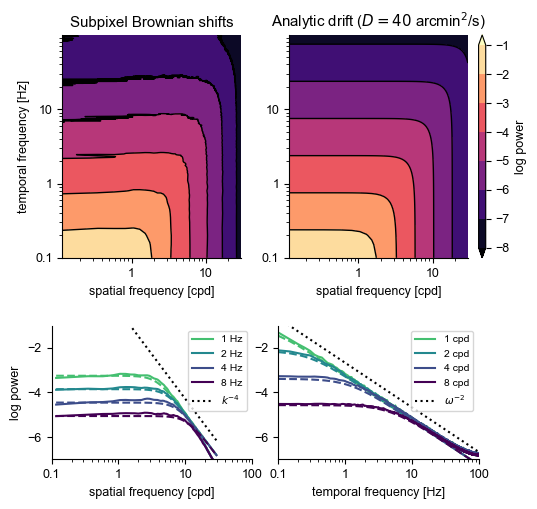

In [4]:
plot_subpix = np.log10(np.clip(power, 1e-12, None))[np.ix_(sf_mask, tf_mask)]
plot_analytic = np.log10(np.clip(Cx_drift(sf_empirical, tf, D_deg, alpha=2.0), 1e-12, None))[
    np.ix_(sf_mask, tf_mask)
]
offset = np.nanmedian(plot_analytic - plot_subpix)
plot_subpix = plot_subpix + offset

levels = np.arange(
    np.floor(np.nanmin([plot_subpix.min(), plot_analytic.min()])),
    np.ceil(np.nanmax([plot_subpix.max(), plot_analytic.max()])) + 1,
)

fig = plt.figure(figsize=(14 * cm, 14 * cm))
g = fig.add_gridspec(2, 4, height_ratios=[1, 0.6], hspace=0.38, wspace=0.3)

ax_emp = fig.add_subplot(g[0, :2])
c_emp = plot_contours(ax_emp, sf_plot, tf_plot, plot_subpix, levels)

ax_analytic = fig.add_subplot(g[0, 2:], sharey=ax_emp)
c_analytic = plot_contours(ax_analytic, sf_plot, tf_plot, plot_analytic, levels)

for ax, title in [
    (ax_emp, "Subpixel Brownian shifts"),
    (ax_analytic, rf"Analytic drift ($D={D_arcmin}$ arcmin$^2$/s)"),
]:
    ax.set(xscale="log", yscale="log", xlabel="spatial frequency [cpd]", title=title)
    ax.set_aspect("equal", adjustable="box")
ax_emp.set_ylabel("temporal frequency [Hz]")

colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(tf_targets)))
ax_spatial = fig.add_subplot(g[1, :2])
for j, target in enumerate(tf_targets):
    i = np.argmin(np.abs(tf_plot - target))
    line = ax_spatial.plot(sf_plot, plot_subpix[:, i], label=f"{tf_plot[i]:.1g} Hz", color=colors[j])[0]
    ax_spatial.plot(sf_plot, plot_analytic[:, i], "--", color=line.get_color())

a = np.argmin(np.abs(sf_plot - 2))
p = max(plot_subpix[a, np.argmin(np.abs(tf_plot - t))] for t in tf_targets) + 1.75
ax_spatial.plot(sf_plot, p - 4 * np.log10(sf_plot / sf_plot[a]), "k:", label=r"$k^{-4}$")

colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(sf_targets)))
ax_temporal = fig.add_subplot(g[1, 2:], sharey=ax_spatial)
for j, target in enumerate(sf_targets):
    i = np.argmin(np.abs(sf_plot - target))
    line = ax_temporal.plot(tf_plot, plot_subpix[i], label=f"{sf_plot[i]:.1g} cpd", color=colors[j])[0]
    ax_temporal.plot(tf_plot, plot_analytic[i], "--", color=line.get_color())

a = np.argmin(np.abs(tf_plot - 2))
p = max(plot_subpix[np.argmin(np.abs(sf_plot - t)), a] for t in sf_targets) + 0.5
ax_temporal.plot(tf_plot, p - 2 * np.log10(tf_plot / tf_plot[a]), "k:", label=r"$\omega^{-2}$")

ax_temporal.set(xscale="log", xlabel="temporal frequency [Hz]")
ax_spatial.set(xscale="log", xlabel="spatial frequency [cpd]", ylabel="log power")
ax_temporal.legend(fontsize="small")
ax_spatial.legend(fontsize="small")
ax_temporal.set_xlim(ylim)
ax_spatial.set_xlim(xlim)

for ax in [ax_emp, ax_analytic, ax_temporal, ax_spatial]:
    ax.xaxis.set_major_formatter(fmt)
for ax in [ax_emp, ax_analytic]:
    ax.yaxis.set_major_formatter(fmt)
for ax in [ax_temporal, ax_spatial]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim([-7, -1])

cax = inset_axes(
    ax_analytic,
    width="4%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.06, 0, 1, 1),
    bbox_transform=ax_analytic.transAxes,
    borderpad=0,
)
fig.colorbar(c_emp, cax=cax, label=r"log power")
fig.savefig(RESULTS / "emp_vs_analytic.pdf")


/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/212310676.py:101: UserWarning: Adding colorbar to a different Figure <Figure size 551.181x551.181 with 7 Axes> than <Figure size 630.709x137.008 with 2 Axes> which fig.colorbar is called on.
  fig.colorbar(c_emp, cax=cax, label=r"log power")


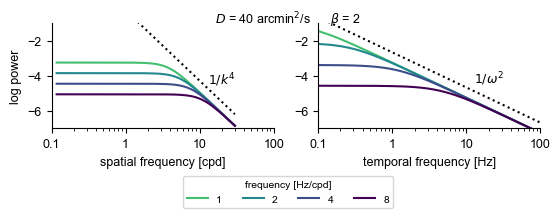

In [23]:
plot_subpix = np.log10(np.clip(power, 1e-12, None))[np.ix_(sf_mask, tf_mask)]
plot_analytic = np.log10(np.clip(Cx_drift(sf_empirical, tf, D_deg, alpha=2.0), 1e-12, None))[
    np.ix_(sf_mask, tf_mask)
]
offset = np.nanmedian(plot_analytic - plot_subpix)
plot_subpix = plot_subpix + offset

levels = np.arange(
    np.floor(np.nanmin([plot_subpix.min(), plot_analytic.min()])),
    np.ceil(np.nanmax([plot_subpix.max(), plot_analytic.max()])) + 1,
)

fig = plt.figure(figsize=(0.9*fw,0.4*hw))
g = fig.add_gridspec(1,2,)
ax_spatial = fig.add_subplot(g[0])
ax_temporal = fig.add_subplot(g[1], sharey=ax_spatial)

# ax_emp = fig.add_subplot(g[0, :2])
# c_emp = plot_contours(ax_emp, sf_plot, tf_plot, plot_subpix, levels)

# ax_analytic = fig.add_subplot(g[0, 2:], sharey=ax_emp)
# c_analytic = plot_contours(ax_analytic, sf_plot, tf_plot, plot_analytic, levels)

# for ax, title in [
#     (ax_emp, "Subpixel Brownian shifts"),
#     (ax_analytic, rf"Analytic drift ($D={D_arcmin}$ arcmin$^2$/s)"),
# ]:
#     ax.set(xscale="log", yscale="log", xlabel="spatial frequency [cpd]", title=title)
#     ax.set_aspect("equal", adjustable="box")
# ax_emp.set_ylabel("temporal frequency [Hz]")

colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(tf_targets)))
for j, target in enumerate(tf_targets):
    i = np.argmin(np.abs(tf_plot - target))
    # line = ax_spatial.plot(sf_plot, plot_subpix[:, i], label=f"{tf_plot[i]:.1g} Hz", color=colors[j])[0]
    # ax_spatial.plot(sf_plot, plot_analytic[:, i], "--", color=line.get_color())
    line = ax_spatial.plot(sf_plot, plot_analytic[:, i], label=f"{tf_plot[i]:.1g} Hz", color=colors[j])[0]

a = np.argmin(np.abs(sf_plot - 2))
p = max(plot_subpix[a, np.argmin(np.abs(tf_plot - t))] for t in tf_targets) + 1.75
ax_spatial.plot(sf_plot, p - 4 * np.log10(sf_plot / sf_plot[a]), "k:", label=r"$k^{-4}$")
ax_spatial.annotate(
    r"$1/k^4$", xy=(20, p - 4 * np.log10(20 / sf_plot[a])),
    xytext=(0, 10), textcoords="offset points",
    ha="center", va="bottom", fontsize="medium",
)

colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(sf_targets)))
for j, target in enumerate(sf_targets):
    i = np.argmin(np.abs(sf_plot - target))
    # line = ax_temporal.plot(tf_plot, plot_subpix[i], label=f"{sf_plot[i]:.1g} cpd", color=colors[j])[0]
    # ax_temporal.plot(tf_plot, plot_analytic[i], "--", color=line.get_color())
    line = ax_temporal.plot(tf_plot, plot_analytic[i], label=f"{sf_plot[i]:.1g}", color=colors[j])[0]

a = np.argmin(np.abs(tf_plot - 2))
p = max(plot_subpix[np.argmin(np.abs(sf_plot - t)), a] for t in sf_targets) + 0.5
ax_temporal.plot(tf_plot, p - 2 * np.log10(tf_plot / tf_plot[a]), "k:",)# label=r"$\omega^{-2}$")
ax_temporal.annotate(
    r"$1/\omega^2$", xy=(20, p - 2 * np.log10(20 / tf_plot[a])),
    xytext=(0, 8), textcoords="offset points",
    ha="center", va="bottom", fontsize="medium",
)

ax_temporal.set(xscale="log", xlabel="temporal frequency [Hz]")
ax_spatial.set(xscale="log", xlabel="spatial frequency [cpd]", ylabel="log power")
# ax_temporal.legend(fontsize="small",title="Frequency [Hz/cpd]",title_fontsize="small",ncol=4)
handles, labels = ax_temporal.get_legend_handles_labels()
fig.legend(
    handles, labels,
    title="frequency [Hz/cpd]",
    fontsize="small",
    title_fontsize="small",
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
)
# ax_spatial.legend(fontsize="small")
ax_temporal.set_xlim(ylim)
ax_spatial.set_xlim(xlim)

for ax in [ax_emp, ax_analytic, ax_temporal, ax_spatial]:
    ax.xaxis.set_major_formatter(fmt)
for ax in [ax_emp, ax_analytic]:
    ax.yaxis.set_major_formatter(fmt)
for ax in [ax_temporal, ax_spatial]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim([-7, -1])

cax = inset_axes(
    ax_analytic,
    width="4%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.06, 0, 1, 1),
    bbox_transform=ax_analytic.transAxes,
    borderpad=0,
)

fig.suptitle(rf"$D$ = 40 arcmin$^2$/s      $\beta$ = 2",fontsize="medium")
fig.colorbar(c_emp, cax=cax, label=r"log power")
fig.savefig(RESULTS / "cross_section.pdf",bbox_inches="tight")


## Fig. `spatial_temporal_spectra_for_different_betas.pdf`

/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/2057810171.py:35: RuntimeWarning: divide by zero encountered in divide
  return 1 / np.sqrt(4 * np.pi * D * t) * np.exp(-x ** 2 / (4 * D * t))
/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/2057810171.py:35: RuntimeWarning: invalid value encountered in multiply
  return 1 / np.sqrt(4 * np.pi * D * t) * np.exp(-x ** 2 / (4 * D * t))
/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/638097838.py:30: RuntimeWarning: divide by zero encountered in log10
  z = np.ma.masked_where(rho <= 0, np.log10(rho))
/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/2057810171.py:95: UserWarning: The following kwargs were not used by contour: 'negative_linestyle'
  ax.contour(x, y, z.T, levels=levels, colors="k", linewidths=lw, linestyles="solid", negative_linestyle="solid")
/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/2057810171.py:95: UserWarning: The following kwargs were

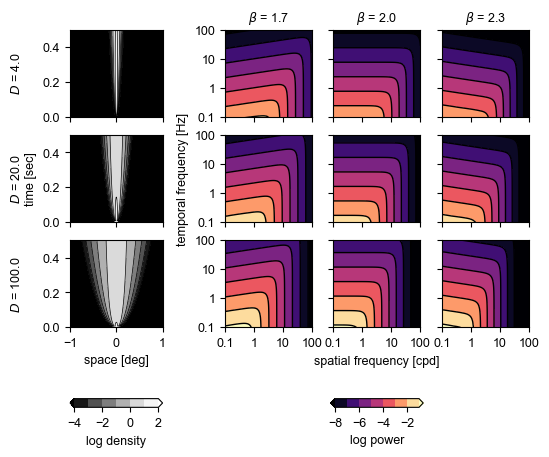

In [6]:
sf_demo = np.linspace(1e-2,100,2000)
tf_demo = np.linspace(1e-2,100,2000)
betas = [1.7, 2.0, 2.3]
D_arcmins_matrix = [4, 20, 100]
ncols = 2 + len(betas)
nrows = len(D_arcmins_matrix)
spec_mid_col = 2 + len(betas) // 2

fig = plt.figure(figsize=(0.85 * fw, 0.7 * fw))
gs = fig.add_gridspec(
    nrows + 2,
    ncols,
    height_ratios=[1] * nrows + [0.4] + [0.1],
    width_ratios=[1] + [0.3] + [1] * len(betas),
    hspace=0.3
)

psd_levels = np.arange(-8, 0, 1)
rho_levels = np.arange(-4, 3, 1)
cf = None
rho_cax = None
for j, D_arcmin_j in enumerate(D_arcmins_matrix):
    D_deg_j = D_arcmin_j / 60.0 ** 2

    ax = fig.add_subplot(gs[j, 0])
    x = np.linspace(-1, 1, 500)
    t = np.linspace(0, 0.5, 100)
    rho = brownian_probability_1d(x[:, None], D_deg_j, t[None, :])
    ax.set_facecolor("black")
    z = np.ma.masked_where(rho <= 0, np.log10(rho))
    rho_cax = plot_contours(ax, x, t, z, rho_levels, lw=0.5, cmap="Greys_r")
    ax.spines["right"].set_visible(True)
    ax.spines["top"].set_visible(True)
    if j == nrows - 1:
        ax.set_xlabel("space [deg]")
    else:
        ax.set_xticklabels([])
        ax.set_xlabel("")
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(t.min(), t.max())
    if j == 1:
        ax.set_ylabel(rf"$D$ = {D_arcmin_j:.1f}" + "\n" + r"time [sec]")
    else:
        ax.set_ylabel(rf"$D$ = {D_arcmin_j:.1f}" + "\n")

    for i, beta in enumerate(betas):
        plot_analytic_beta = np.log10(np.clip(Cx_drift(sf_demo, tf_demo, D_deg_j, alpha=beta), 1e-12, None)) #[np.ix_(sf_mask, tf_mask)]
        ax = fig.add_subplot(gs[j, i + 2])
        cf = plot_contours(ax, sf_demo, tf_demo, plot_analytic_beta, psd_levels)# , lw=0.5)
        ax.spines["right"].set_visible(True)
        ax.spines["top"].set_visible(True)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.minorticks_off()
        ax.xaxis.set_major_formatter(fmt)
        ax.yaxis.set_major_formatter(fmt)
        ax.set_xlim([0.1,100])
        ax.set_ylim([0.1,100])
        if j == 0:
            ax.set_title(f"$\\beta$ = {beta:.1f}", fontsize=9)

        if j != nrows - 1:
            ax.set_xticklabels([])
        if i != 0:
            ax.set_yticklabels([])
            ax.set_ylabel("")
        elif j == 1:
            ax.set_ylabel("temporal frequency [Hz]")
        ax.set_aspect("equal")
        if j == nrows - 1 and i == len(betas) // 2:
            ax.set_xlabel("spatial frequency [cpd]")

for col in range(ncols):
    if col not in (0, spec_mid_col):
        fig.add_subplot(gs[nrows, col]).set_axis_off()

ax_cbar_rho = fig.add_subplot(gs[-1, 0])
cbar_rho = fig.colorbar(rho_cax, cax=ax_cbar_rho, orientation="horizontal", label=r"log density")
ticks = cbar_rho.ax.get_xticks()
cbar_rho.ax.set_xticks(ticks[::2] if len(ticks) > 2 else ticks)

ax_cbar_cf = fig.add_subplot(gs[-1, spec_mid_col])
cbar_cf = fig.colorbar(cf, cax=ax_cbar_cf, orientation="horizontal", label=r"log power")
ticks = cbar_cf.ax.get_xticks()
cbar_cf.ax.set_xticks(ticks[::2] if len(ticks) > 2 else ticks)

fig.savefig(RESULTS / "spatial_temporal_spectra_for_different_betas.pdf")


## Fig. `optimal_filter.pdf`

In [7]:
etas = np.logspace(-5,-2,10)

d_stars = [] # deg
for i, eta in enumerate(etas):
    d_star = find_diffusion_constant_give_eta(
        sf, tf, weights, N_in, N_out, eta, alpha=2.0, 
        separable=False, temporal_cost_function=temporal_cost_function,delta=0.001
    )    
    d_stars.append(d_star)

<>:4: SyntaxWarning: invalid escape sequence '\e'
<>:4: SyntaxWarning: invalid escape sequence '\e'
/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/3972937002.py:4: SyntaxWarning: invalid escape sequence '\e'
  xlabel="temporal constraint $\eta$",


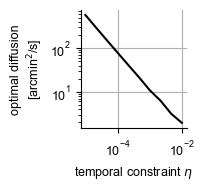

In [27]:
fig,ax = plt.subplots(figsize=( 0.4 * hw, 0.45*hw))
ax.plot(etas,np.asarray(d_stars)*60**2,c="k")
ax.set(
    xlabel="temporal constraint $\eta$",
    ylabel=f"optimal diffusion\n[arcmin$^2$/s]",
    yscale="log",
    xscale="log",
    # aspect="equal"
)
ax.grid()
plt.savefig(RESULTS / "D_as_function_of_eta.pdf",bbox_inches="tight")

In [28]:

temporal_cost = etas[np.abs(np.asarray(d_stars)*60**2 - 40).argmin()]
print(temporal_cost)

0.00021544346900318823


I(Z;R) = 870.1 nats


/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/1916992004.py:95: UserWarning: The following kwargs were not used by contour: 'negative_linestyle'
  ax.contour(x, y, z.T, levels=levels, colors="k", linewidths=lw, linestyles="solid", negative_linestyle="solid")


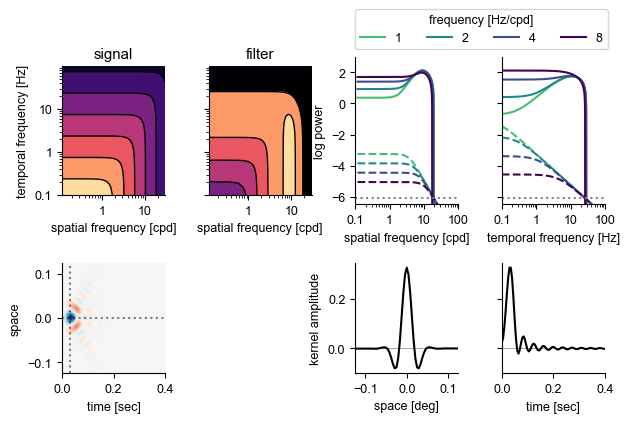

In [29]:
Cx, v_opt, MI = mutual_information(
    sf, tf, weights, D_deg, N_in, N_out, alpha,
    c=temporal_cost, temporal_cost_function=temporal_cost_function,
)
print(f"I(Z;R) = {MI:.4g} nats")
plot_and_save_optimal_filter(v_opt,fname="optimal_filter.pdf",max_space = 0.125,max_time=0.4,ylim_slice=(-6.5,3))

5.7591763151781936e-08
I(Z;R) = 1234 nats


/var/folders/hy/7cxjc3qx1vsfk45ckcv7_w3h0000gn/T/ipykernel_67969/1916992004.py:95: UserWarning: The following kwargs were not used by contour: 'negative_linestyle'
  ax.contour(x, y, z.T, levels=levels, colors="k", linewidths=lw, linestyles="solid", negative_linestyle="solid")


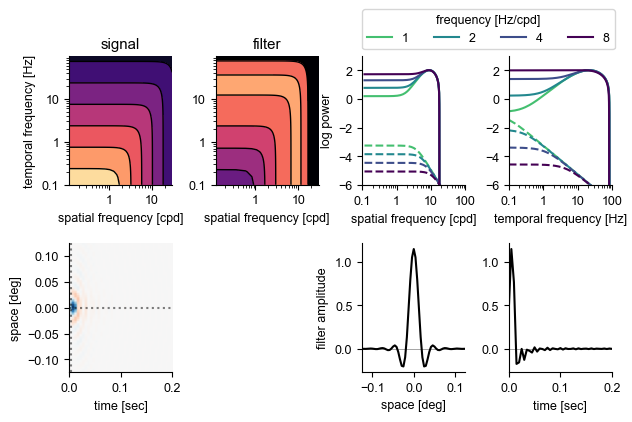

In [30]:
eta_star = find_eta_given_diffusion_constant(
    sf, tf, weights, D_deg, N_in, N_out, alpha,
    temporal_cost_function=temporal_cost_function, delta=1e-7
)
print(eta_star)

Cx, v_opt, MI = mutual_information(
    sf, tf, weights, D_deg, N_in, N_out, alpha,
    c=eta_star, temporal_cost_function=temporal_cost_function,
)
print(f"I(Z;R) = {MI:.4g} nats")

plot_filter = np.log10(np.clip(v_opt, 1e-12, None))[np.ix_(sf_mask, tf_mask)]
filter_levels = np.arange(-4.1, np.ceil(np.nanmax([plot_filter.max()])) + 1, 1)
max_time = 0.2
max_space = 0.125

fig = plt.figure(figsize=(fw, 1.2 * hw))
g = fig.add_gridspec(2, 4, hspace=0.45, wspace=0.42)

ax_signal = fig.add_subplot(g[0, 0])
c_signal = plot_contours(ax_signal, sf_plot, tf_plot, plot_analytic, levels)

ax_filter = fig.add_subplot(g[0, 1], sharey=ax_signal)
c_filter = plot_contours(ax_filter, sf_plot, tf_plot, plot_filter, filter_levels)

w_xt_plot, x, t = compute_space_time_filter(v_opt, T, dt, dx, K)
ax_kernel = fig.add_subplot(g[1, :1])
vmag = np.abs(w_xt_plot).max()
ax_kernel.imshow(
    w_xt_plot, aspect="auto", origin="lower",
    extent=[t[0], t[-1], x[0], x[-1]], cmap="RdBu", vmin=-vmag, vmax=vmag,
)
ax_kernel.set_xlabel("time [sec]")
ax_kernel.set_ylabel("space [deg]")
ax_kernel.set_xlim([0, max_time])
ax_kernel.set_ylim([-max_space, max_space])

ax_spatial_slice = fig.add_subplot(g[1, 2])
arg_slice = w_xt_plot[w_xt_plot.shape[0] // 2, :].argmax()
spatial_slice = w_xt_plot[:, arg_slice]
ax_kernel.axvline(t[arg_slice], color="k", alpha=0.5, linestyle=":")
ax_spatial_slice.plot(x, spatial_slice, c="k")
ax_spatial_slice.axhline(0, color="k", alpha=0.5, linewidth=0.5)
ax_spatial_slice.set_xlim([-max_space, max_space])
ax_spatial_slice.set_xlabel("space [deg]")
ax_spatial_slice.set_ylabel("filter amplitude")
ymin, ymax = ax_spatial_slice.get_ylim()

ax_temporal_slice = fig.add_subplot(g[1, 3])
ax_temporal_slice.plot(t, w_xt_plot[w_xt_plot.shape[0] // 2, :], c="k")
ax_temporal_slice.set_xlabel("time [sec]")
ax_temporal_slice.set_xlim([0, max_time])
ax_temporal_slice.set_ylim([ymin, ymax])
ax_temporal_slice.axhline(0, color="k", alpha=0.5, linewidth=0.5)
ax_kernel.axhline(0, color="k", alpha=0.5, linestyle=":")

for ax, title in [(ax_filter, "filter"), (ax_signal, "signal")]:
    ax.set(xscale="log", yscale="log", xlabel="spatial frequency [cpd]", title=title)
    ax.set_aspect("equal", adjustable="box")
ax_signal.set_ylabel("temporal frequency [Hz]")

colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(tf_targets)))
ax_spatial = fig.add_subplot(g[0, 2])
for j, target in enumerate(tf_targets):
    i = np.argmin(np.abs(tf_plot - target))
    line = ax_spatial.plot(sf_plot, plot_filter[:, i], label=f"{tf_plot[i]:.1g}", color=colors[j])[0]
    ax_spatial.plot(sf_plot, plot_analytic[:, i], "--", color=line.get_color())

colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(sf_targets)))
ax_temporal = fig.add_subplot(g[0, 3], sharey=ax_spatial)
for j, target in enumerate(sf_targets):
    i = np.argmin(np.abs(sf_plot - target))
    line = ax_temporal.plot(tf_plot, plot_filter[i], label=f"{sf_plot[i]:.1g}", color=colors[j])[0]
    ax_temporal.plot(tf_plot, plot_analytic[i], "--", color=line.get_color())

ax_temporal.set(xscale="log", xlabel="temporal frequency [Hz]")
ax_spatial.set(xscale="log", xlabel="spatial frequency [cpd]", ylabel="log power")
ax_spatial.legend(ncol=4, loc=(0.0, 1.05), title="frequency [Hz/cpd]")
ax_temporal.set_xlim(ylim)
ax_spatial.set_xlim(xlim)

for ax in [ax_filter, ax_temporal, ax_spatial, ax_signal]:
    ax.xaxis.set_major_formatter(fmt)
for ax in [ax_filter, ax_signal]:
    ax.yaxis.set_major_formatter(fmt)
for ax in [ax_temporal, ax_spatial]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.axhline(np.log10(N_in), color="grey", linestyle=":")
    ax.set_ylim([-6, 3])

fig.savefig(RESULTS / "optimal_filter_eta=0.pdf")


## Fig. `optimal_diffusion_constant_vs_input_output_noise.pdf`

Left: mutual information in nats (linear scale) vs $D$ (log scale) for $\sigma_{\mathrm{in}}=0.15, 0.20, 0.25$, at $\sigma_{\mathrm{out}}=2$. Stars mark the sampled maxima.

Right: $\log_{10}D^*$ across input and output noise, using the original notebook’s noise grid and diffusion sweep. Noise standard deviations are converted to PSDs using $N=\sigma^2/A$, as in the model setup above. The MI axis follows the current model normalization rather than the older figure’s fixed limits.


In [18]:
from scipy.optimize import minimize_scalar


def mi_at_diffusion(D_arcmin, N_in, N_out):
    """Information rate at D in arcmin^2/s, with the filter reoptimized."""
    _, _, MI = mutual_information(
        sf, tf, weights, D_arcmin / 60.0 ** 2, N_in, N_out, alpha,
        c=temporal_cost, temporal_cost_function=temporal_cost_function,
    )
    return MI


def find_optimal_diffusion(N_in, N_out, D_bounds, rel_tol=0.03):
    """Return D* and MI*; target ~3% precision in D for a single-peaked curve."""
    result = minimize_scalar(
        lambda log_D: -mi_at_diffusion(10.0 ** log_D, N_in, N_out),
        bounds=np.log10(D_bounds),
        method="bounded",
        options={"xatol": np.log10(1.0 + rel_tol)},
    )
    if not result.success:
        raise RuntimeError(result.message)

    # Include endpoints in case the best value is at a search boundary.
    candidates = [D_bounds[0], 10.0 ** result.x, D_bounds[1]]
    values = [
        mi_at_diffusion(D_bounds[0], N_in, N_out),
        -result.fun,
        mi_at_diffusion(D_bounds[1], N_in, N_out),
    ]
    best = int(np.argmax(values))
    return candidates[best], values[best]


# Original noise grid (without the duplicated sigma_out = 0.5 row).
sigma_ins_sweep = np.r_[0.01, np.arange(0.05, 0.41, 0.05)]
sigma_outs_sweep = np.arange(0.5, 3.01, 0.5)
sigma_ins_curves = [0.1, 0.20, 0.3]
sigma_out_fixed = 2.0
D_bounds = (10.0 ** -1.3, 10.0 ** 3.5)  # arcmin^2/s
D_arcmins = np.geomspace(*D_bounds, 80)  # For plotting only.

shape = (len(sigma_ins_sweep), len(sigma_outs_sweep))
D_opt_arr = np.empty(shape)
MI_opt_arr = np.empty(shape)
# Axes: input noise, output noise, diffusion constant.
# Only the displayed curves are evaluated; other entries remain NaN.
all_MI_arr = np.full((*shape, len(D_arcmins)), np.nan)
for i, sigma_in_i in enumerate(tqdm(sigma_ins_sweep, desc="Optimize diffusion")):
    for j, sigma_out_j in enumerate(sigma_outs_sweep):
        # mutual_information expects noise PSDs, not standard deviations.
        N_in_i = sigma_in_i ** 2 / spectral_area
        N_out_j = sigma_out_j ** 2 / spectral_area
        D_opt_arr[i, j], MI_opt_arr[i, j] = find_optimal_diffusion(
            N_in_i, N_out_j, D_bounds,
        )

# Dense curves are needed only for the three lines shown in the next plots.
j_out = int(np.flatnonzero(np.isclose(sigma_outs_sweep, sigma_out_fixed))[0])
for sigma_in_i in tqdm(sigma_ins_curves, desc="MI curves"):
    i = int(np.flatnonzero(np.isclose(sigma_ins_sweep, sigma_in_i))[0])
    N_in_i = sigma_in_i ** 2 / spectral_area
    N_out_j = sigma_outs_sweep[j_out] ** 2 / spectral_area
    all_MI_arr[i, j_out] = [
        mi_at_diffusion(D, N_in_i, N_out_j) for D in D_arcmins
    ]


MI curves: 100%|██████████| 3/3 [00:22<00:00,  7.54s/it]


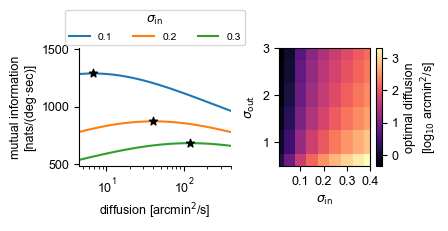

In [19]:
fig, axs = plt.subplots(
    1, 2, figsize=(0.65 * fw, 0.7 * hw), width_ratios=[0.8, 0.6],
)
# colors = mpl.cm.viridis_r(np.linspace(0.3, 1, len(sigma_ins_curves)))

ax = axs[0]
j_out = int(np.flatnonzero(np.isclose(sigma_outs_sweep, sigma_out_fixed))[0])
for i,sigma_in_i in enumerate(sigma_ins_curves):
    q = int(np.flatnonzero(np.isclose(sigma_ins_sweep, sigma_in_i))[0])
    MI_vals = all_MI_arr[q, j_out]
    ax.plot(D_arcmins, MI_vals,label=f"{sigma_in_i}")
    ax.scatter(D_opt_arr[q, j_out], MI_opt_arr[q, j_out], marker="*",c="k", zorder=3)
    # ax.annotate(
    #     rf"$\sigma_{{\mathrm{{in}}}}={sigma_in_i:.2g}$",
    #     (D_opt_arr[q, j_out], MI_opt_arr[q, j_out]),
    #     xytext=(0, 6), textcoords="offset points", ha="center",
    # )
# ax.legend(title=r"$\sigma_{in}$",ncol=3,)
ax.legend(
    title=r"$\sigma_{\mathrm{in}}$",
    ncol=3,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    borderaxespad=0,
    fontsize="small"
)
ax.xaxis.set_major_formatter(plain_formatter())

ax.set_xlabel(r"diffusion [arcmin$^2$/s]")
ax.set_ylabel("mutual information\n[nats/(deg·sec)]")
ax.set_xscale("log")
ax.set_yscale("linear")
ax.yaxis.set_major_formatter(plain_formatter())
# Keep the original window unless an optimized maximum falls outside it.
curve_indices = [int(np.flatnonzero(np.isclose(sigma_ins_sweep, s))[0]) for s in sigma_ins_curves]
curve_optima = D_opt_arr[curve_indices, j_out]
ax.set_xlim(min(8, curve_optima.min() / 1.5), max(400, curve_optima.max() * 1.5))
visible = (D_arcmins >= ax.get_xlim()[0]) & (D_arcmins <= ax.get_xlim()[1])
visible_MI = all_MI_arr[curve_indices, j_out][:, visible]
mi_min = visible_MI.min()
mi_max = max(visible_MI.max(), MI_opt_arr[curve_indices, j_out].max())
mi_span = mi_max - mi_min
ax.set_ylim(mi_min - 0.08 * mi_span, mi_max + 0.3 * mi_span)

ax = axs[1]
pcm = ax.pcolormesh(
    sigma_ins_sweep, sigma_outs_sweep, np.log10(D_opt_arr.T),
    shading="nearest", cmap="magma",
)
cbar = fig.colorbar(pcm, ax=ax)
cbar.set_label(f"optimal diffusion\n[log$_{{10}}$ arcmin$^2$/s]")
ax.set_xlabel(r"$\sigma_{\mathrm{in}}$")
ax.set_ylabel(r"$\sigma_{\mathrm{out}}$")
ax.set_xlim(sigma_ins_sweep[0], sigma_ins_sweep[-1])
ax.set_ylim(sigma_outs_sweep[0], sigma_outs_sweep[-1])
ax.set_xticks([0.1, 0.2, 0.3, 0.4])
ax.set_yticks([1, 2, 3])
ax.xaxis.set_major_formatter(plain_formatter())
ax.yaxis.set_major_formatter(plain_formatter())
ax.spines["right"].set_visible(True)
ax.spines["top"].set_visible(True)

fig.tight_layout()
fig.savefig(RESULTS / "optimal_diffusion_constant_vs_input_output_noise.pdf", bbox_inches="tight")
plt.show()


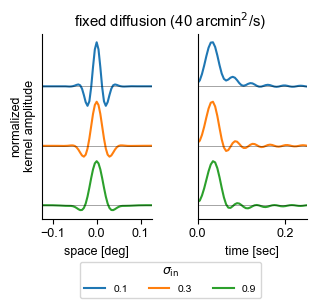

In [20]:
## increase the input noise but keep everythign else fixed 
max_time = 0.25
max_space = 0.125
fig = plt.figure(figsize=(hw, 0.7*hw))
g = fig.add_gridspec(1, 2, hspace=0.45, wspace=0.42)
ax_temporal_slice = fig.add_subplot(g[1])
ax_spatial_slice = fig.add_subplot(g[0],sharey=ax_temporal_slice)
sigma_ins_curves = [0.1, 0.30, 0.9]


for i,sigma_in_i in enumerate(sigma_ins_curves):
    
    N_in = sigma_in_i ** 2 / spectral_area
    Cx, v_opt, MI = mutual_information(
        sf, tf, weights, D_deg, N_in, N_out, alpha,
        c=temporal_cost, temporal_cost_function=temporal_cost_function,
    )
    w_xt_plot, x, t = compute_space_time_filter(v_opt, T, dt, dx, K) 
    ofs = -1.35*i

    arg_slice = w_xt_plot[w_xt_plot.shape[0] // 2, :].argmax()
    spatial_slice = w_xt_plot[:, arg_slice]
    y = spatial_slice
    ax_spatial_slice.plot(x, ofs+y/y.max(), label=f"{sigma_in_i}")
    # ax_spatial_slice.plot(x, y, label=f"{sigma_in_i}")
    ax_spatial_slice.axhline(ofs, color="k", alpha=0.5, linewidth=0.5)
    ax_spatial_slice.set_xlim([-max_space, max_space])
    ax_spatial_slice.set_xlabel("space [deg]")
    ax_spatial_slice.set_ylabel("normalized\nkernel amplitude")
    ymin, ymax = ax_spatial_slice.get_ylim()

    y = w_xt_plot[w_xt_plot.shape[0] // 2, :]
    ax_temporal_slice.plot(t,ofs+y/y.max(), label=f"{sigma_in_i}")
    # ax_temporal_slice.plot(t, y, label=f"{sigma_in_i}")
    ax_temporal_slice.set_xlabel("time [sec]")
    ax_temporal_slice.set_xlim([0, max_time])
    # ax_temporal_slice.set_ylim([ymin, ymax])
    ax_temporal_slice.axhline(ofs, color="k", alpha=0.5, linewidth=0.5)
ax_temporal_slice.set_yticks([])

handles, labels = ax_temporal_slice.get_legend_handles_labels()
fig.legend(
    handles, labels,
    title=r"$\sigma_{\mathrm{in}}$",
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    fontsize="small"
)
fig.suptitle("fixed diffusion (40 arcmin$^2$/s)")
plt.savefig(RESULTS / "vary_noise_redlich.pdf",bbox_inches="tight")


6.756165111961769
40.58216616338245
120.36658090394796


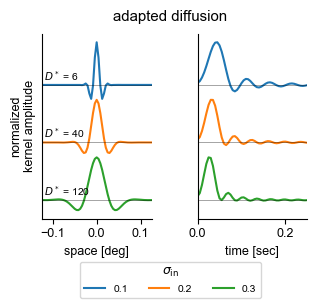

In [22]:
## increase the input noise but keep everythign else fixed 
max_time = 0.25
max_space = 0.125
fig = plt.figure(figsize=(1*hw, 0.7*hw))
g = fig.add_gridspec(1, 2, hspace=0.45, wspace=0.42)
ax_temporal_slice = fig.add_subplot(g[1])
ax_spatial_slice = fig.add_subplot(g[0],sharey=ax_temporal_slice)
sigma_ins_curves = [0.1, 0.2, 0.3]


for k,sigma_in_i in enumerate(sigma_ins_curves):
    i = int(np.flatnonzero(np.isclose(sigma_ins_sweep, sigma_in_i))[0])
    D_arcmin = D_opt_arr[i, j_out]
    ofs = -1.35*k
    
    print(D_arcmin)

    N_in = sigma_in_i ** 2 / spectral_area
    Cx, v_opt, MI = mutual_information(
        sf, tf, weights, D_arcmin/60**2, N_in, N_out, alpha,
        c=temporal_cost, temporal_cost_function=temporal_cost_function,
    )
    w_xt_plot, x, t = compute_space_time_filter(v_opt, T, dt, dx, K)


    arg_slice = w_xt_plot[w_xt_plot.shape[0] // 2, :].argmax()
    spatial_slice = w_xt_plot[:, arg_slice]
    y = spatial_slice
    ax_spatial_slice.plot(x, ofs+y/y.max(), label=f"{sigma_in_i}")
    ax_spatial_slice.text(-0.12,ofs+0.1,f"$D^*$ = {int(D_arcmin)}",fontsize="small")
    # ax_spatial_slice.plot(x, y, label=f"{sigma_in_i}")
    ax_spatial_slice.axhline(ofs, color="k", alpha=0.5, linewidth=0.5)
    ax_spatial_slice.set_xlim([-max_space, max_space])
    ax_spatial_slice.set_xlabel("space [deg]")
    ax_spatial_slice.set_ylabel("normalized\nkernel amplitude")
    ymin, ymax = ax_spatial_slice.get_ylim()

    y = w_xt_plot[w_xt_plot.shape[0] // 2, :]
    ax_temporal_slice.plot(t,ofs+ y/y.max(), label=f"{sigma_in_i}")
    # ax_temporal_slice.plot(t, y, label=f"{sigma_in_i}")
    ax_temporal_slice.set_xlabel("time [sec]")
    ax_temporal_slice.set_xlim([0, max_time])
    # ax_temporal_slice.set_ylim([ymin, ymax])
    ax_temporal_slice.axhline(ofs, color="k", alpha=0.5, linewidth=0.5)
ax_temporal_slice.set_yticks([])

# ax_temporal_slice.legend(title="$\sigma_{in}$",ncol=3)
handles, labels = ax_temporal_slice.get_legend_handles_labels()
fig.legend(
    handles, labels,
    title=r"$\sigma_{\mathrm{in}}$",
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    fontsize="small"
)
fig.suptitle("adapted diffusion")
plt.savefig(RESULTS / "vary_noise_redlich_adapted.pdf",bbox_inches="tight")
